In [ ]:
import pandas as pd

data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Data"
)

print(data.head())
print(data.columns)

   Year  Distirct  Latitude  Longitude     x1     x2     x3    x4       x5  \
0  2017   Barguna   23.7073    90.4155  25.24  81.62  34.21  7.28  4904.30   
1  2018   Barguna   23.7073    90.4155  25.06  78.94  35.40  7.01  2779.10   
2  2019   Barguna   23.7073    90.4155  25.67  77.44  39.74  8.76  2990.04   
3  2020   Barguna   23.7073    90.4155  25.11  81.00  36.73  8.15  2884.57   
4  2017  Barishal   22.7004    90.3750  25.42  83.12  33.30  8.90  6570.70   

      x6  ...  y11  y12  y13  y14  y15   y16   y17  y18  y19   y20  
0  16.95  ...    0    0  122  139    0  1681   2.0   29    0  1944  
1  12.45  ...    0    0   37  272    0  5136   7.0   13    4  5452  
2  16.20  ...    0    0  274  340    1  5394  12.0   48  316  6021  
3  20.59  ...    0    0   20  202    0  3727  14.0   10    2  3963  
4  15.11  ...    0    0  192  246    0  4561   6.0   23    4  5005  

[5 rows x 31 columns]
Index(['Year', 'Distirct', 'Latitude', 'Longitude', 'x1', 'x2', 'x3', 'x4',
       'x5', 'x6',

In [1]:
import pandas as pd
import numpy as np

# 1. Load Dataset
data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Data"
)

# 2. Dataset Overview
print("Dataset Shape:", data.shape)
print("\nFirst 5 Observations:")
print(data.head())

# 3. Column Information
print("\nColumn Names:")
print(data.columns.tolist())

# 4. Data Types
print("\nData Types:")
print(data.dtypes)

# 5. Statistical Summary
print("\nDescriptive Statistics:")
print(data.describe())

# 6. Missing Values
print("\nMissing Values:")
print(data.isnull().sum())

# 7. Duplicate Values
print("\nDuplicate Rows:", data.duplicated().sum())

# 8. Unique Values
print("\nUnique Values:")
print(data.nunique())

# 9. Total Missing Values
print("\nTotal Missing Values:", data.isnull().sum().sum())

# 10. Dataset Information
print("\nDataset Information:")
data.info()

Dataset Shape: (256, 31)

First 5 Observations:
   Year  Distirct  Latitude  Longitude     x1     x2     x3    x4       x5  \
0  2017   Barguna   23.7073    90.4155  25.24  81.62  34.21  7.28  4904.30   
1  2018   Barguna   23.7073    90.4155  25.06  78.94  35.40  7.01  2779.10   
2  2019   Barguna   23.7073    90.4155  25.67  77.44  39.74  8.76  2990.04   
3  2020   Barguna   23.7073    90.4155  25.11  81.00  36.73  8.15  2884.57   
4  2017  Barishal   22.7004    90.3750  25.42  83.12  33.30  8.90  6570.70   

      x6  ...  y11  y12  y13  y14  y15   y16   y17  y18  y19   y20  
0  16.95  ...    0    0  122  139    0  1681   2.0   29    0  1944  
1  12.45  ...    0    0   37  272    0  5136   7.0   13    4  5452  
2  16.20  ...    0    0  274  340    1  5394  12.0   48  316  6021  
3  20.59  ...    0    0   20  202    0  3727  14.0   10    2  3963  
4  15.11  ...    0    0  192  246    0  4561   6.0   23    4  5005  

[5 rows x 31 columns]

Column Names:
['Year', 'Distirct', 'Latitude'

Dataset Loaded Successfully!
Dataset Shape: (256, 31)

SPATIAL ANALYSIS RESULTS

Getis-Ord Gi* Results:
    District  Gi_Z_Score
     Barguna    0.699274
    Barishal    0.061701
       Bhola   -0.102834
  Jhalokathi    0.143968
  Patuakhali   -0.884377
    Pirojpur   -0.946077
   Bandarban    4.257348
Brahmanbaria   -0.329070
    Chandpur   -0.843243
  Chittagong    3.146735
 Cox's bazar    4.421883
     Cumilla   -0.102834
        Feni    0.041134
 Khagrachari    2.591429
  Lakshmipur   -0.555306
    Noakhali   -0.473039
   Rangamati    2.180091
       Dhaka    0.102834
    Faridpur   -0.760975
     Gazipur   -0.020567
   Gopalgonj   -0.843243
 Kishoreganj   -0.740408
   Madaripur   -0.925510
   Manikganj    0.514172
  Munshiganj    0.041134
 Narayanganj    0.370204
  Narshingdi    0.637574
     Rajbari   -0.267370
  Shariatpur   -0.637574
     Tangail   -0.164535
    Bagerhat   -0.555306
   Chuadanga    0.082268
     Jessore   -0.617007
   Jhenaidah   -0.061701
      Khulna   -0.555

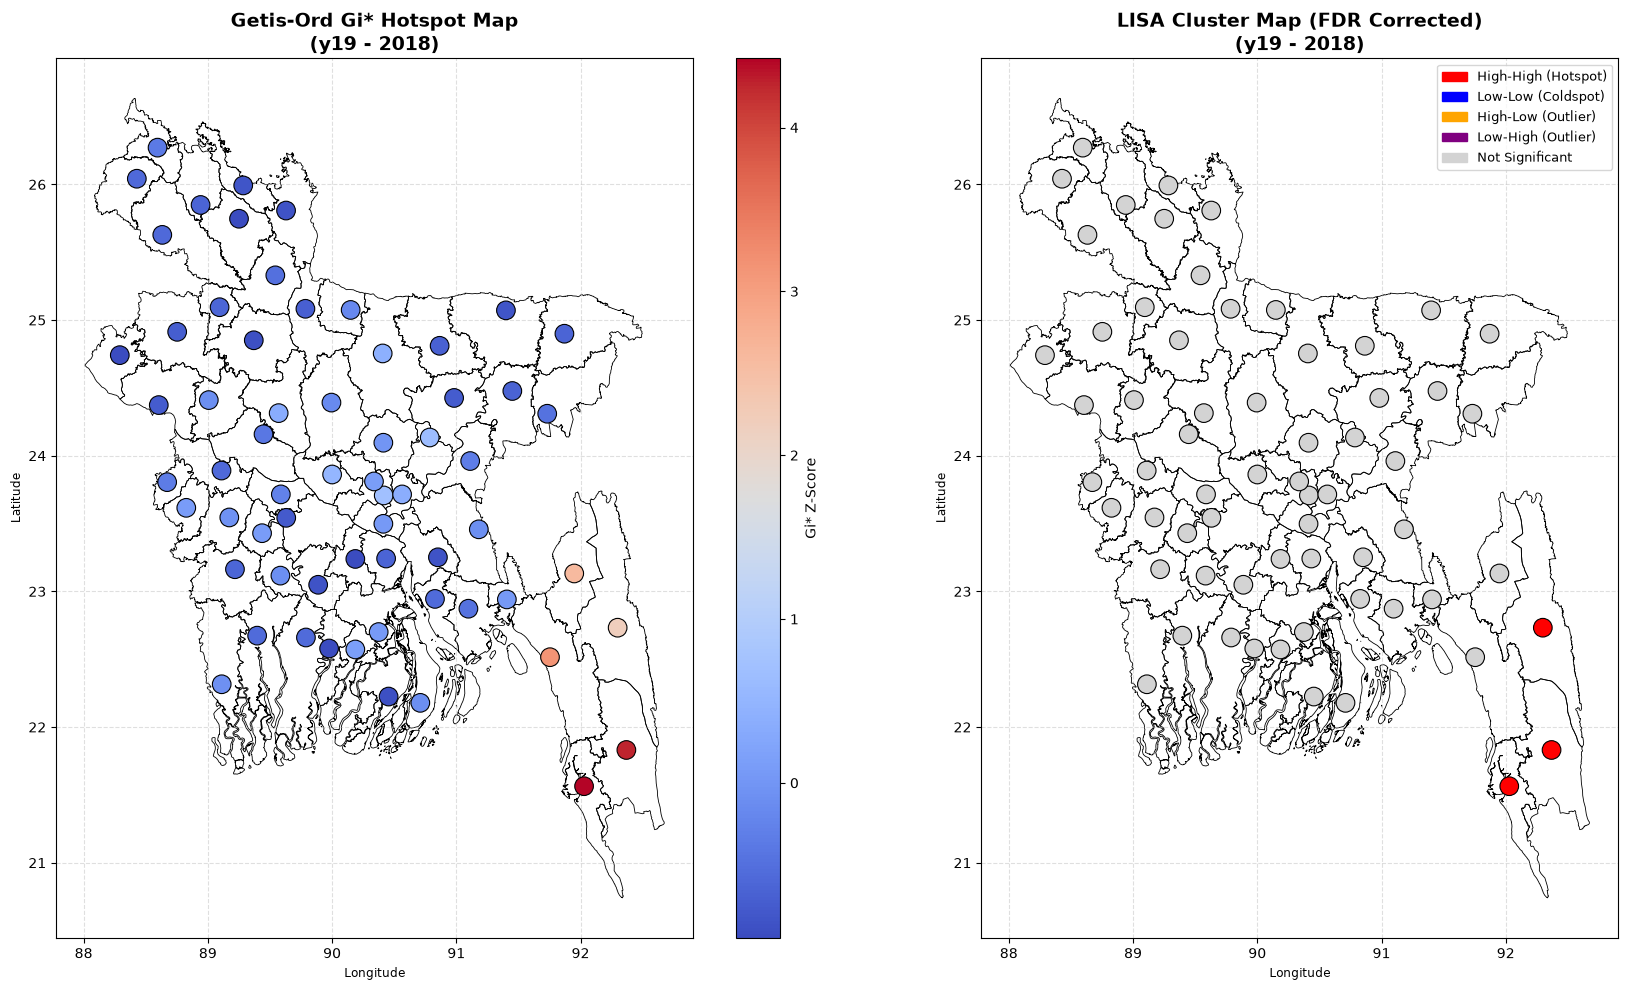


Analysis Completed Successfully!
Map saved: Spatial_Hotspot_LISA_Analysis.png
Results saved: Spatial_Analysis_Results.xlsx
Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [6]:
# ============================================================
# SPATIAL HOTSPOT ANALYSIS OF INFECTIOUS DISEASES IN BANGLADESH
# Getis-Ord Gi* and Local Moran's I (LISA)
# ============================================================

import os
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

from sklearn.neighbors import NearestNeighbors
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "Infectious Disease Data (1).xlsx"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Excel file not found! Place the Excel file in the "
        "same folder as your Jupyter Notebook."
    )

df = pd.read_excel(file_path, sheet_name="Data")

df.columns = df.columns.str.strip()

if "Distirct" in df.columns:
    df.rename(columns={"Distirct": "District"}, inplace=True)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# ============================================================
# 2. SELECT YEAR AND DISEASE
# ============================================================

year_to_analyze = 2018
disease_col = "y19"

df_year = df[df["Year"] == year_to_analyze].copy()

df_year[disease_col] = pd.to_numeric(
    df_year[disease_col], errors="coerce"
).fillna(0)

df_year["Longitude"] = pd.to_numeric(
    df_year["Longitude"], errors="coerce"
)

df_year["Latitude"] = pd.to_numeric(
    df_year["Latitude"], errors="coerce"
)

df_year = df_year.dropna(
    subset=["Longitude", "Latitude"]
).reset_index(drop=True)

# ============================================================
# 3. SPATIAL COORDINATES
# ============================================================

coords = df_year[["Longitude", "Latitude"]].values
y = df_year[disease_col].values

n = len(y)
k = 4

if n <= k:
    raise ValueError("Insufficient observations for KNN.")

if np.std(y) == 0:
    raise ValueError("Disease values have zero variance.")

# ============================================================
# 4. SPATIAL WEIGHTS MATRIX (KNN)
# ============================================================

nbrs = NearestNeighbors(n_neighbors=k + 1).fit(coords)

distances, indices = nbrs.kneighbors(coords)

W = np.zeros((n, n))

for i, neighbors in enumerate(indices):
    for j in neighbors[1:]:
        W[i, j] = 1 / k

# ============================================================
# 5. GETIS-ORD GI* Z-SCORE
# ============================================================

mean_y = np.mean(y)
std_y = np.std(y, ddof=1)

gi_z_scores = np.zeros(n)

for i in range(n):

    sum_w_x = np.sum(W[i] * y)
    sum_w = np.sum(W[i])
    sum_w2 = np.sum(W[i] ** 2)

    S = np.sqrt(
        (n * sum_w2 - sum_w ** 2) / (n - 1)
    )

    if S > 0:
        gi_z_scores[i] = (
            sum_w_x - mean_y * sum_w
        ) / (std_y * S)

# ============================================================
# 6. LOCAL MORAN'S I (LISA)
# ============================================================

y_std = (y - mean_y) / std_y

spatial_lag = np.dot(W, y_std)

local_moran_i = y_std * spatial_lag

# ============================================================
# 7. PERMUTATION TEST
# ============================================================

np.random.seed(42)

n_permutations = 999

perm_local_moran = np.zeros((n_permutations, n))

for p in range(n_permutations):

    y_perm = np.random.permutation(y_std)

    perm_local_moran[p, :] = (
        y_perm * np.dot(W, y_perm)
    )

p_values = np.zeros(n)

for i in range(n):

    p_values[i] = (
        np.sum(
            np.abs(perm_local_moran[:, i])
            >= abs(local_moran_i[i])
        ) + 1
    ) / (n_permutations + 1)

# ============================================================
# 8. FDR CORRECTION
# ============================================================

rejected, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

# ============================================================
# 9. LISA CLUSTER CLASSIFICATION
# ============================================================

cluster = []

for i in range(n):

    if not rejected[i]:
        cluster.append("Not Significant")

    elif y_std[i] > 0 and spatial_lag[i] > 0:
        cluster.append("High-High (Hotspot)")

    elif y_std[i] < 0 and spatial_lag[i] < 0:
        cluster.append("Low-Low (Coldspot)")

    elif y_std[i] > 0 and spatial_lag[i] < 0:
        cluster.append("High-Low (Outlier)")

    else:
        cluster.append("Low-High (Outlier)")

# Store results

df_year["Gi_Z_Score"] = gi_z_scores
df_year["Local_Moran_I"] = local_moran_i
df_year["P_Value"] = p_values
df_year["Adjusted_P_Value"] = p_adjusted
df_year["Significant"] = rejected
df_year["LISA_Cluster"] = cluster

# ============================================================
# 10. LOAD BANGLADESH DISTRICT MAP
# ============================================================

url = (
    "https://geodata.ucdavis.edu/gadm/gadm4.1/"
    "json/gadm41_BGD_2.json"
)

bd_map = gpd.read_file(url)

# ============================================================
# 11. DISPLAY RESULTS
# ============================================================

print("\nSPATIAL ANALYSIS RESULTS")
print("=" * 60)

print("\nGetis-Ord Gi* Results:")

print(
    df_year[["District", "Gi_Z_Score"]].to_string(index=False)
)

print("\nLISA Results:")

print(
    df_year[
        [
            "District",
            "Local_Moran_I",
            "P_Value",
            "Adjusted_P_Value",
            "LISA_Cluster"
        ]
    ].to_string(index=False)
)

print("\nLISA Cluster Summary:")

print(df_year["LISA_Cluster"].value_counts())

# ============================================================
# 12. PROFESSIONAL SPATIAL MAP VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Bangladesh boundary

for ax in axes:

    bd_map.plot(
        ax=ax,
        color="none",
        edgecolor="black",
        linewidth=0.6,
        zorder=1
    )

# LEFT MAP: GETIS-ORD GI*

sc1 = axes[0].scatter(
    df_year["Longitude"],
    df_year["Latitude"],
    c=df_year["Gi_Z_Score"],
    cmap="coolwarm",
    s=180,
    edgecolors="black",
    linewidths=0.8,
    zorder=5
)

axes[0].set_title(
    f"Getis-Ord Gi* Hotspot Map\n"
    f"({disease_col} - {year_to_analyze})",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

fig.colorbar(
    sc1,
    ax=axes[0],
    label="Gi* Z-Score"
)

axes[0].grid(
    True,
    linestyle="--",
    alpha=0.4
)

# RIGHT MAP: LISA CLUSTER MAP

color_dict = {
    "High-High (Hotspot)": "red",
    "Low-Low (Coldspot)": "blue",
    "High-Low (Outlier)": "orange",
    "Low-High (Outlier)": "purple",
    "Not Significant": "lightgrey"
}

colors = [
    color_dict[c]
    for c in df_year["LISA_Cluster"]
]

axes[1].scatter(
    df_year["Longitude"],
    df_year["Latitude"],
    c=colors,
    s=180,
    edgecolors="black",
    linewidths=0.8,
    zorder=5
)

axes[1].set_title(
    f"LISA Cluster Map (FDR Corrected)\n"
    f"({disease_col} - {year_to_analyze})",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

axes[1].grid(
    True,
    linestyle="--",
    alpha=0.4
)

# LEGEND

patches = [
    mpatches.Patch(
        color=color,
        label=label
    )
    for label, color in color_dict.items()
]

axes[1].legend(
    handles=patches,
    loc="best",
    fontsize=9
)

plt.tight_layout()

# SAVE MAP

plt.savefig(
    "Spatial_Hotspot_LISA_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. EXPORT RESULTS
# ============================================================

df_year.to_excel(
    "Spatial_Analysis_Results.xlsx",
    index=False
)

print("\nAnalysis Completed Successfully!")

print("Map saved: Spatial_Hotspot_LISA_Analysis.png")

print("Results saved: Spatial_Analysis_Results.xlsx")
### Required Libraries
!pip install geopandas matplotlib numpy pandas scikit-learn statsmodels openpyxl

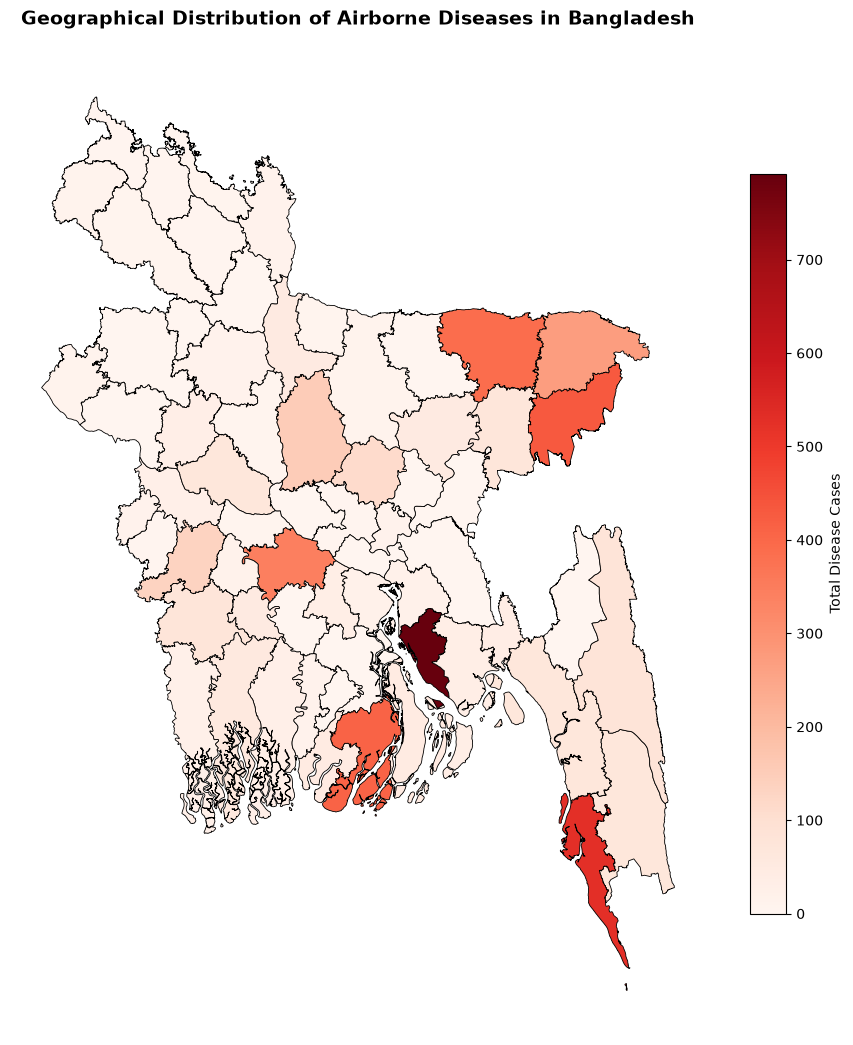

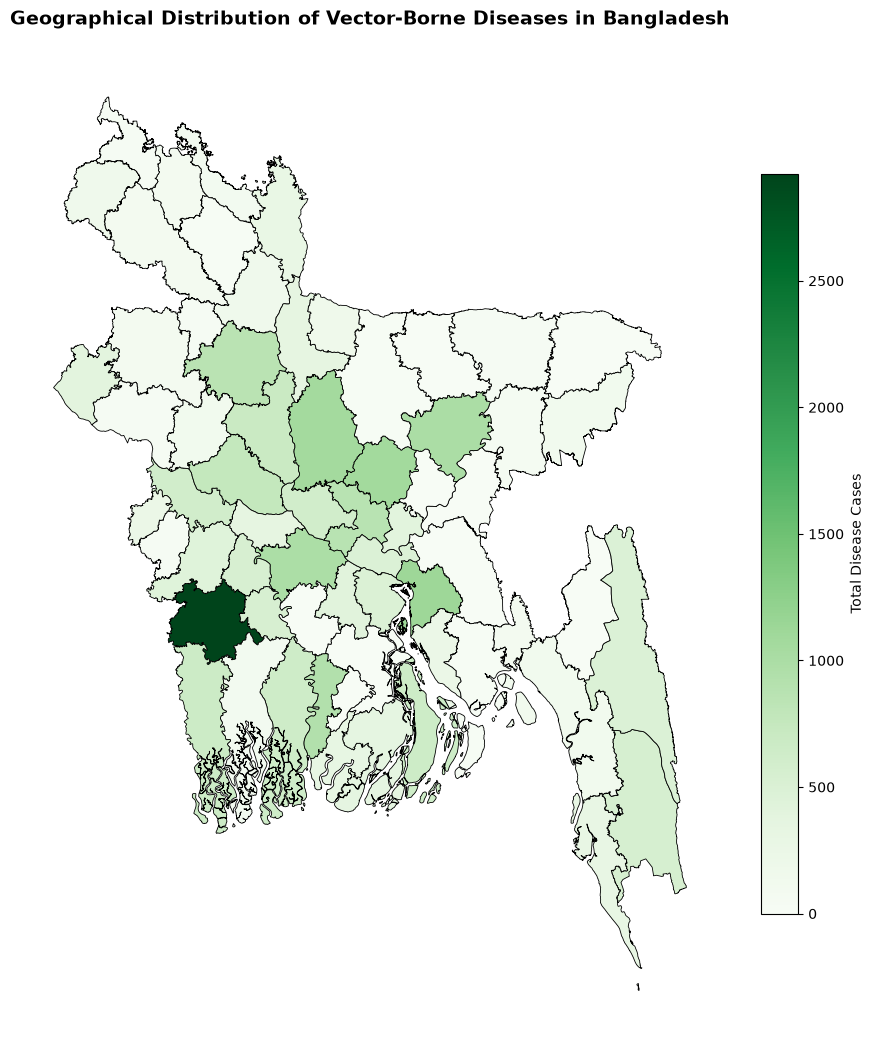

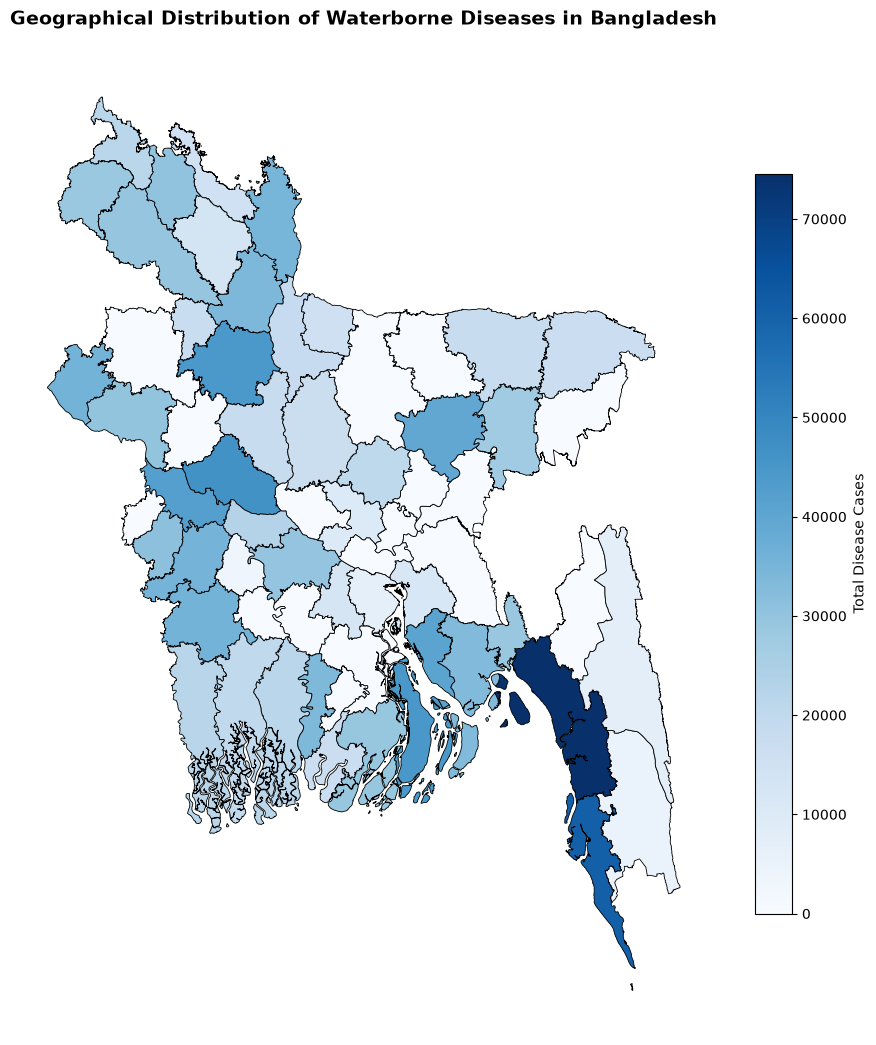

All Three Disease Maps Generated Successfully!


In [7]:
# ==========================================
# 1. Import Libraries
# ==========================================

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import re

# ==========================================
# 2. Load Dataset
# ==========================================

data = pd.read_excel("Infectious Disease Data (1).xlsx")

# ==========================================
# 3. Load Bangladesh Map
# ==========================================

url = "https://www.geoboundaries.org/api/current/gbOpen/BGD/ADM2/"

response = requests.get(url)
response.raise_for_status()

boundary_info = response.json()

geojson_url = boundary_info['gjDownloadURL']

geojson_response = requests.get(geojson_url)
geojson_response.raise_for_status()

geojson_data = geojson_response.json()

bangladesh = gpd.GeoDataFrame.from_features(
    geojson_data['features'],
    crs="EPSG:4326"
)

# ==========================================
# 4. Define Disease Categories
# ==========================================

categories = {
    'Airborne Diseases': {
        'diseases': ['y2'],
        'color': 'Reds'
    },

    'Vector-Borne Diseases': {
        'diseases': ['y7', 'y9'],
        'color': 'Greens'
    },

    'Waterborne Diseases': {
        'diseases': ['y14', 'y16'],
        'color': 'Blues'
    }
}

# ==========================================
# 5. Clean District Names
# ==========================================

def clean_name(name):

    name = str(name).lower().strip()

    name = re.sub(r'[^a-z]', '', name)

    name = re.sub(r'district$', '', name)

    return name


district_col = 'Distirct'
map_col = 'shapeName'

bangladesh['key'] = bangladesh[map_col].apply(clean_name)

# ==========================================
# 6. Create Three Bangladesh Maps
# ==========================================

for category, details in categories.items():

    disease_columns = details['diseases']

    # Convert disease columns to numeric
    for col in disease_columns:
        data[col] = pd.to_numeric(
            data[col],
            errors='coerce'
        ).fillna(0)

    # Calculate total cases by district
    category_data = data.groupby(district_col)[
        disease_columns
    ].sum().reset_index()

    # Total cases of each category
    category_data['Total_Cases'] = category_data[
        disease_columns
    ].sum(axis=1)

    # Clean district names
    category_data['key'] = category_data[
        district_col
    ].apply(clean_name)

    # Merge with Bangladesh map
    map_data = bangladesh.merge(
        category_data[['key', 'Total_Cases']],
        on='key',
        how='left'
    )

    map_data['Total_Cases'] = map_data[
        'Total_Cases'
    ].fillna(0)

    # ======================================
    # 7. Plot Map
    # ======================================

    fig, ax = plt.subplots(figsize=(9, 11))

    map_data.plot(
        column='Total_Cases',
        cmap=details['color'],
        linewidth=0.6,
        edgecolor='black',
        legend=True,
        legend_kwds={
            'label': 'Total Disease Cases',
            'shrink': 0.7
        },
        ax=ax,
        missing_kwds={
            'color': 'lightgrey'
        }
    )

    ax.set_title(
        f'Geographical Distribution of {category} in Bangladesh',
        fontsize=14,
        fontweight='bold',
        pad=20
    )

    ax.set_axis_off()

    plt.tight_layout()

    # Save individual maps
    filename = category.replace('-', '_').replace(' ', '_')

    plt.savefig(
        f'{filename}_Bangladesh_Map.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

print("All Three Disease Maps Generated Successfully!")

File Found: c:\Users\ALPHA TECH\Downloads\STAT4104\Infectious Disease Data (1).xlsx
Dataset Loaded Successfully!
Dataset Shape: (256, 31)

SPEARMAN CORRELATION MATRIX
                     Airborne (y18)  Vector-borne (y19)  Waterborne (y20)
Mean Temp (x1)                0.141               0.350             0.252
Rel. Humidity (x2)            0.092              -0.241            -0.141
Max Temp (x3)                -0.042               0.335             0.019
Min Temp (x4)                 0.215               0.127             0.013
Precipitation (x5)            0.184              -0.074            -0.022
Max Wind Speed (x6)           0.108               0.017             0.012
Min Wind Speed (x7)           0.032               0.084             0.120

P-VALUE MATRIX
                     Airborne (y18)  Vector-borne (y19)  Waterborne (y20)
Mean Temp (x1)               0.0239              0.0000            0.0000
Rel. Humidity (x2)           0.1418              0.0001            0.0237
Max

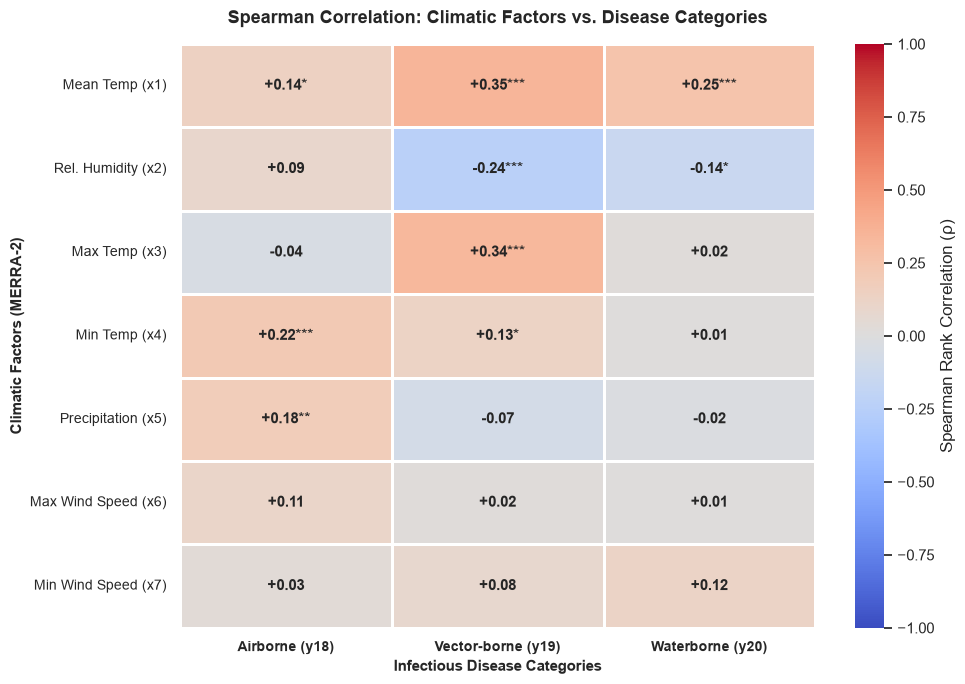


Analysis Completed Successfully!
Heatmap saved successfully!
Excel results exported successfully!


In [9]:
import os
import glob
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# 1. LOAD DATASET AUTOMATICALLY
# =====================================================

file_names = [
    "Infectious Disease Data.xlsx",
    "Infectious Disease Data (1).xlsx"
]

search_paths = [
    os.getcwd(),
    os.path.join(os.path.expanduser("~"), "Desktop"),
    os.path.join(os.path.expanduser("~"), "Downloads")
]

file_path = None

for folder in search_paths:
    for name in file_names:
        candidate = os.path.join(folder, name)

        if os.path.exists(candidate):
            file_path = candidate
            break

    if file_path:
        break

if file_path is None:
    raise FileNotFoundError(
        "Excel file not found. Please place the file "
        "in the Notebook folder, Desktop, or Downloads."
    )

print("File Found:", file_path)

data = pd.read_excel(file_path, sheet_name="Data")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", data.shape)

# =====================================================
# 2. DEFINE VARIABLES
# =====================================================

climate_cols = [
    'x1', 'x2', 'x3', 'x4',
    'x5', 'x6', 'x7'
]

climate_labels = [
    'Mean Temp (x1)',
    'Rel. Humidity (x2)',
    'Max Temp (x3)',
    'Min Temp (x4)',
    'Precipitation (x5)',
    'Max Wind Speed (x6)',
    'Min Wind Speed (x7)'
]

disease_cols = ['y18', 'y19', 'y20']

disease_labels = [
    'Airborne (y18)',
    'Vector-borne (y19)',
    'Waterborne (y20)'
]

# =====================================================
# 3. CHECK AND CONVERT DATA
# =====================================================

required_cols = climate_cols + disease_cols

missing_cols = [
    col for col in required_cols if col not in data.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

for col in required_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# =====================================================
# 4. SPEARMAN CORRELATION
# =====================================================

corr_numeric = pd.DataFrame(
    index=climate_labels,
    columns=disease_labels,
    dtype=float
)

p_values = pd.DataFrame(
    index=climate_labels,
    columns=disease_labels,
    dtype=float
)

corr_text = pd.DataFrame(
    index=climate_labels,
    columns=disease_labels,
    dtype=object
)

for i, clim in enumerate(climate_cols):

    for j, dis in enumerate(disease_cols):

        temp = data[[clim, dis]].dropna()

        if len(temp) < 3:
            rho, p = np.nan, np.nan

        elif temp[clim].nunique() < 2 or temp[dis].nunique() < 2:
            rho, p = np.nan, np.nan

        else:
            rho, p = stats.spearmanr(
                temp[clim], temp[dis]
            )

        corr_numeric.iloc[i, j] = rho
        p_values.iloc[i, j] = p

        if pd.isna(p):
            sig = ""
        elif p < 0.001:
            sig = "***"
        elif p < 0.01:
            sig = "**"
        elif p < 0.05:
            sig = "*"
        else:
            sig = ""

        corr_text.iloc[i, j] = (
            f"{rho:+.2f}{sig}" if pd.notna(rho) else "NA"
        )

# =====================================================
# 5. DISPLAY RESULTS
# =====================================================

print("\nSPEARMAN CORRELATION MATRIX")
print(corr_numeric.round(3))

print("\nP-VALUE MATRIX")
print(p_values.round(4))

print("\nCORRELATION WITH SIGNIFICANCE")
print(corr_text)

# =====================================================
# 6. HEATMAP VISUALIZATION
# =====================================================

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_numeric,
    annot=corr_text,
    fmt='',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={
        'label': 'Spearman Rank Correlation (ρ)'
    },
    linewidths=1,
    linecolor='white',
    annot_kws={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    'Spearman Correlation: Climatic Factors vs. Disease Categories',
    fontsize=13,
    fontweight='bold',
    pad=15
)

plt.xlabel(
    'Infectious Disease Categories',
    fontsize=11,
    fontweight='bold'
)

plt.ylabel(
    'Climatic Factors (MERRA-2)',
    fontsize=11,
    fontweight='bold'
)

plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, rotation=0)

plt.tight_layout()

# =====================================================
# 7. SAVE FIGURE
# =====================================================

plt.savefig(
    'climatic_disease_correlation_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# =====================================================
# 8. EXPORT RESULTS
# =====================================================

corr_numeric.to_excel(
    'Spearman_Correlation_Results.xlsx'
)

p_values.to_excel(
    'Spearman_P_Values.xlsx'
)

print("\nAnalysis Completed Successfully!")
print("Heatmap saved successfully!")
print("Excel results exported successfully!")

Dataset found: c:\Users\ALPHA TECH\Downloads\STAT4104\Infectious Disease Data (1).xlsx


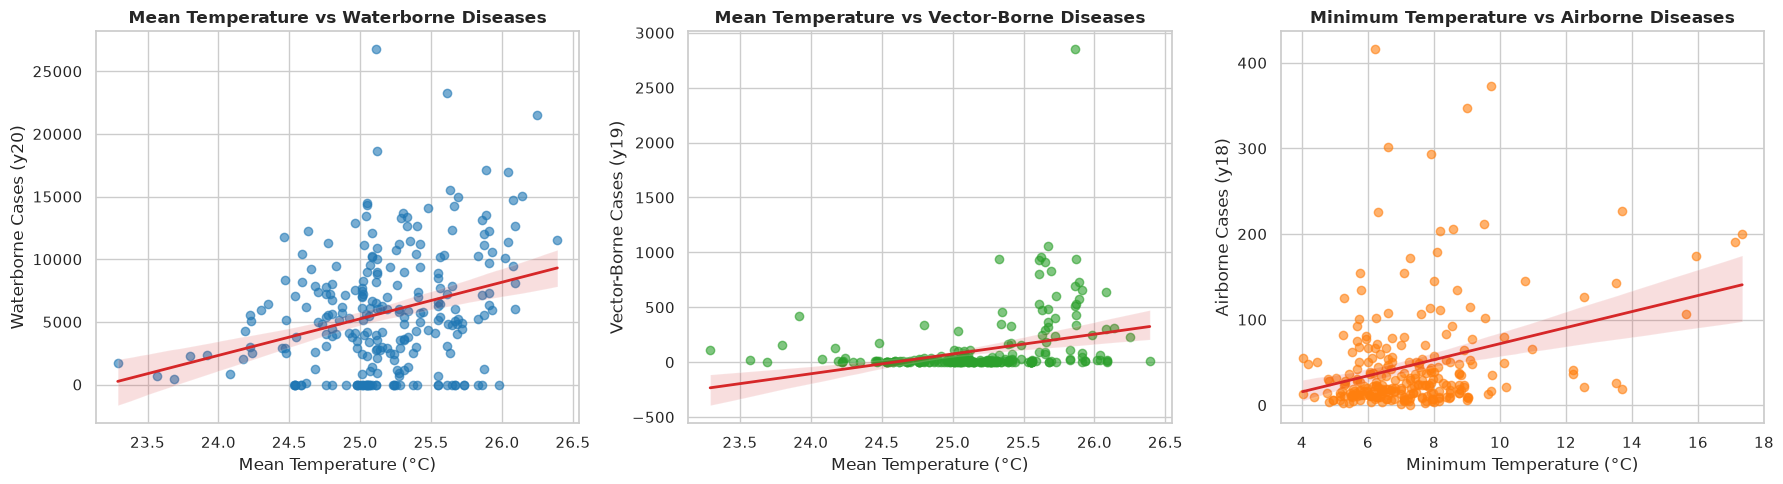

Figure saved successfully!
Output location: c:\Users\ALPHA TECH\Downloads\STAT4104\climatic_disease_associations.png


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tkinter import Tk, filedialog

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.family': 'sans-serif'
})

# 1. Automatically find the Excel dataset
file_names = [
    "Infectious Disease Data.xlsx",
    "Infectious Disease Data (1).xlsx",
    "Infectious Disease Data (1)(1).xlsx",
    "Infectious Disease Data (1)(3).xlsx"
]

search_folders = [
    os.getcwd(),
    os.path.join(os.path.expanduser("~"), "Desktop"),
    os.path.join(os.path.expanduser("~"), "Downloads")
]

file_path = None

for folder in search_folders:
    for file_name in file_names:
        possible_path = os.path.join(folder, file_name)

        if os.path.exists(possible_path):
            file_path = possible_path
            break

    if file_path:
        break

# If file is not found, open file selection window
if file_path is None:
    print("Dataset not found automatically. Please select your Excel file.")

    root = Tk()
    root.withdraw()

    file_path = filedialog.askopenfilename(
        title="Select Infectious Disease Dataset",
        filetypes=[("Excel Files", "*.xlsx *.xls")]
    )

    root.destroy()

if not file_path:
    raise FileNotFoundError("No Excel dataset selected!")

print("Dataset found:", file_path)

# 2. Load dataset
data = pd.read_excel(file_path, sheet_name="Data")

# 3. Check required columns
required_columns = ['x1', 'x4', 'y18', 'y19', 'y20']

missing_columns = [
    col for col in required_columns if col not in data.columns
]

if missing_columns:
    raise ValueError(f"Missing columns in dataset: {missing_columns}")

# 4. Convert variables into numeric format
for col in required_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 5. Construct disease category totals
data['Airborne_Total'] = data['y18']
data['Vector_Total'] = data['y19']
data['Waterborne_Total'] = data['y20']

# 6. Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Mean Temperature vs Waterborne Diseases
sns.regplot(
    data=data,
    x='x1',
    y='Waterborne_Total',
    ax=axes[0],
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)

axes[0].set_title(
    'Mean Temperature vs Waterborne Diseases',
    fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Mean Temperature (°C)')
axes[0].set_ylabel('Waterborne Cases (y20)')

# Subplot 2: Mean Temperature vs Vector-Borne Diseases
sns.regplot(
    data=data,
    x='x1',
    y='Vector_Total',
    ax=axes[1],
    scatter_kws={'alpha': 0.6, 'color': '#2ca02c'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)

axes[1].set_title(
    'Mean Temperature vs Vector-Borne Diseases',
    fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Mean Temperature (°C)')
axes[1].set_ylabel('Vector-Borne Cases (y19)')

# Subplot 3: Minimum Temperature vs Airborne Diseases
sns.regplot(
    data=data,
    x='x4',
    y='Airborne_Total',
    ax=axes[2],
    scatter_kws={'alpha': 0.6, 'color': '#ff7f0e'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)

axes[2].set_title(
    'Minimum Temperature vs Airborne Diseases',
    fontsize=12, fontweight='bold'
)
axes[2].set_xlabel('Minimum Temperature (°C)')
axes[2].set_ylabel('Airborne Cases (y18)')

# 7. Adjust layout and save figure
plt.tight_layout()

output_file = os.path.join(
    os.path.dirname(file_path),
    'climatic_disease_associations.png'
)

plt.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved successfully!")
print("Output location:", output_file)

In [20]:
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP

In [27]:
import pandas as pd

data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Data"
)

print("Available Sheets:")
excel = pd.ExcelFile("Infectious Disease Data (1).xlsx")
print(excel.sheet_names)

print("\nActual Column Names:")
print(data.columns.tolist())

print("\nFirst 5 Rows:")
print(data.head())

Available Sheets:
['Data', 'Variable description']

Actual Column Names:
['Year', 'Distirct', 'Latitude', 'Longitude', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'y9', 'y10', 'y11', 'y12', 'y13', 'y14', 'y15', 'y16', 'y17', 'y18', 'y19', 'y20']

First 5 Rows:
   Year  Distirct  Latitude  Longitude     x1     x2     x3    x4       x5  \
0  2017   Barguna   23.7073    90.4155  25.24  81.62  34.21  7.28  4904.30   
1  2018   Barguna   23.7073    90.4155  25.06  78.94  35.40  7.01  2779.10   
2  2019   Barguna   23.7073    90.4155  25.67  77.44  39.74  8.76  2990.04   
3  2020   Barguna   23.7073    90.4155  25.11  81.00  36.73  8.15  2884.57   
4  2017  Barishal   22.7004    90.3750  25.42  83.12  33.30  8.90  6570.70   

      x6  ...  y11  y12  y13  y14  y15   y16   y17  y18  y19   y20  
0  16.95  ...    0    0  122  139    0  1681   2.0   29    0  1944  
1  12.45  ...    0    0   37  272    0  5136   7.0   13    4  5452  
2  16.20  ...    

In [28]:
import pandas as pd

data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Variable description"
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print(data.to_string(index=False))

                 Type     Codes                                               Description
     Spatial temporal      Year                                                      Year
                  NaN  Distirct                                            District names
                  NaN  Latitude                                           Latitude values
                  NaN Longitude                                          Longitude values
              Climate        x1                       MERRA-2 Temperature at 2 Meters (C)
                  NaN        x2                 MERRA-2 Relative Humidity at 2 Meters (%)
                  NaN        x3              MERRA-2 Temperature at 2 Meters Maximum (C) 
                  NaN        x4              MERRA-2 Temperature at 2 Meters Minimum (C) 
                  NaN        x5                      MERRA-2 Precipitation Corrected (mm)
                  NaN        x6              MERRA-2 Wind speed at 50 Meters Maximum (C) 
          

Dataset Shape: (256, 31)
   Year  Distirct  Latitude  Longitude     x1     x2     x3    x4       x5  \
0  2017   Barguna   23.7073    90.4155  25.24  81.62  34.21  7.28  4904.30   
1  2018   Barguna   23.7073    90.4155  25.06  78.94  35.40  7.01  2779.10   
2  2019   Barguna   23.7073    90.4155  25.67  77.44  39.74  8.76  2990.04   
3  2020   Barguna   23.7073    90.4155  25.11  81.00  36.73  8.15  2884.57   
4  2017  Barishal   22.7004    90.3750  25.42  83.12  33.30  8.90  6570.70   

      x6    x7  y1  y2  y3  y4  y5  y6   y7  y8  y9  y10  y11  y12  y13  y14  \
0  16.95  0.04   0  12   4   0  13   0    0   0   0    0    0    0  122  139   
1  12.45  0.06   0   4   2   0   6   1    3   0   0    1    0    0   37  272   
2  16.20  0.11   1  26   9   0   9   3  316   0   0    0    0    0  274  340   
3  20.59  0.02   0   5   2   0   3   0    2   0   0    0    0    0   20  202   
4  15.11  0.09   0   1   1  11  10   0    0   3   1    0    0    0  192  246   

   y15   y16   y17  y18  

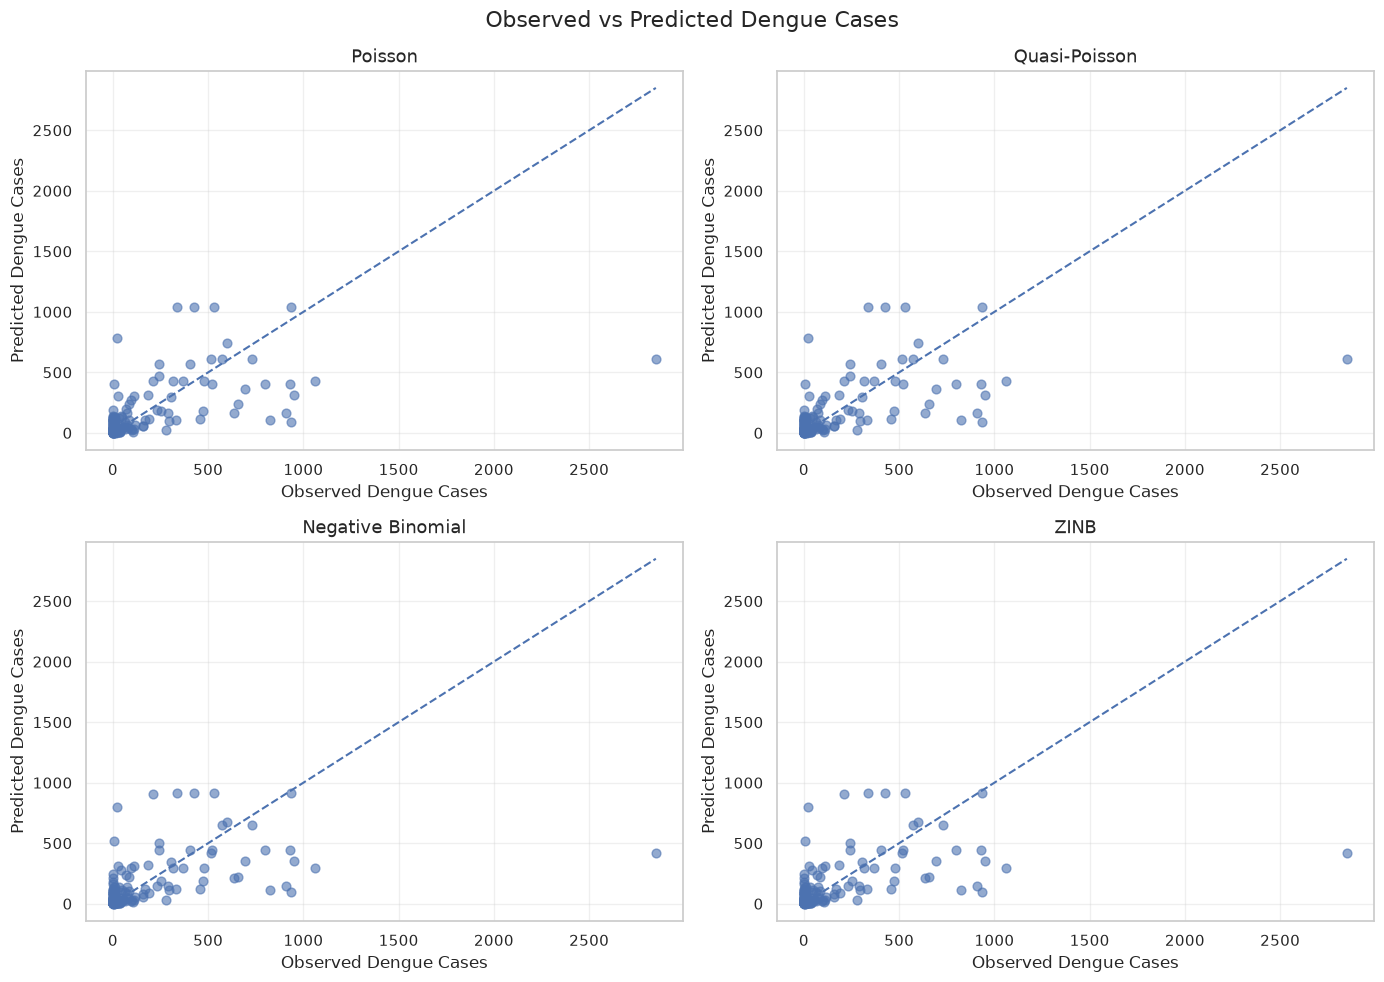


========== PREDICTION SUMMARY ==========

 Poisson
count     256.000000
mean       98.613281
std       183.340961
min         1.771599
25%         9.890915
50%        25.995666
75%        96.220943
max      1043.072909
dtype: float64

 Quasi-Poisson
count     256.000000
mean       98.613281
std       183.340961
min         1.771599
25%         9.890915
50%        25.995666
75%        96.220943
max      1043.072909
dtype: float64

 Negative Binomial
count    256.000000
mean      94.019032
std      175.226470
min        1.047255
25%        9.054294
50%       19.970845
75%       87.868143
max      916.720379
dtype: float64

 ZINB
count    256.000000
mean      94.017163
std      175.222800
min        1.047255
25%        9.054417
50%       19.970675
75%       87.866838
max      916.700788
dtype: float64

All Models Fitted Successfully!
Dengue Model Comparison Graph Generated!


In [29]:
# ==================================================
# 1. IMPORT LIBRARIES
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler

from statsmodels.discrete.discrete_model import NegativeBinomial
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP


# ==================================================
# 2. IMPORT DATASET
# ==================================================

data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Data"
)

print("Dataset Shape:", data.shape)
print(data.head())


# ==================================================
# 3. SELECT VARIABLES
# ==================================================

# Dependent Variable: Dengue

target = "y7"

# Independent Variables

predictors = [
    "x1", "x2", "x3", "x4",
    "x5", "x6", "x7"
]

df = data[[target] + predictors].copy()

# Convert to Numeric

for col in [target] + predictors:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna()

# Response Variable

y = df[target]

if (y < 0).any() or not np.allclose(y, np.round(y)):
    raise ValueError("Dengue count must be non-negative integers.")

y = y.astype(int)


# ==================================================
# 4. STANDARDIZE INDEPENDENT VARIABLES
# ==================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[predictors])

X = pd.DataFrame(
    X_scaled,
    columns=predictors,
    index=df.index
)

X = sm.add_constant(X, has_constant="add")

print("\nObservations:", len(y))
print("Predictors:", predictors)


# ==================================================
# 5. POISSON REGRESSION
# ==================================================

print("\n========== POISSON REGRESSION ==========")

poisson_model = sm.GLM(
    y,
    X,
    family=sm.families.Poisson()
).fit()

pred_poisson = poisson_model.predict(X)

print(poisson_model.summary())


# ==================================================
# 6. QUASI-POISSON REGRESSION
# ==================================================

print("\n========== QUASI-POISSON REGRESSION ==========")

quasi_model = sm.GLM(
    y,
    X,
    family=sm.families.Poisson()
).fit(scale="X2")

pred_quasi = quasi_model.predict(X)

print(quasi_model.summary())


# ==================================================
# 7. NEGATIVE BINOMIAL REGRESSION
# ==================================================

print("\n========== NEGATIVE BINOMIAL REGRESSION ==========")

nb_model = NegativeBinomial(
    y,
    X
).fit(
    method="bfgs",
    maxiter=2000,
    disp=0
)

pred_nb = nb_model.predict(X)

print(nb_model.summary())


# ==================================================
# 8. ZERO-INFLATED NEGATIVE BINOMIAL (ZINB)
# ==================================================

print("\n========== ZINB REGRESSION ==========")

# Inflation Model

Z = np.ones((len(y), 1))

# Fit ZINB Model

zinb_model = ZeroInflatedNegativeBinomialP(
    endog=y,
    exog=X,
    exog_infl=Z,
    inflation="logit",
    p=2
).fit(
    method="bfgs",
    maxiter=3000,
    disp=0
)

# ZINB Prediction

pred_zinb = zinb_model.predict(
    exog=X,
    exog_infl=Z,
    which="mean"
)

print(zinb_model.summary())


# ==================================================
# 9. MODEL CONVERGENCE
# ==================================================

print("\n========== MODEL CONVERGENCE ==========")

print("Poisson:", poisson_model.converged)

print("Quasi-Poisson:", quasi_model.converged)

print(
    "Negative Binomial:",
    nb_model.mle_retvals.get("converged", False)
)

print(
    "ZINB:",
    zinb_model.mle_retvals.get("converged", False)
)


# ==================================================
# 10. MODEL DIAGNOSTICS
# ==================================================

print("\n========== MODEL DIAGNOSTICS ==========")

# Poisson Dispersion

poisson_dispersion = (
    poisson_model.pearson_chi2 /
    poisson_model.df_resid
)

print("Poisson Dispersion:", poisson_dispersion)

# Quasi-Poisson Dispersion

print("Quasi-Poisson Dispersion:", quasi_model.scale)

# Negative Binomial Alpha

print("Negative Binomial Alpha:", nb_model.params["alpha"])

# ZINB Alpha

print("ZINB Alpha:", zinb_model.params["alpha"])


# ==================================================
# 11. OBSERVED VS PREDICTED VALUES
# ==================================================

predictions = {
    "Poisson": np.asarray(pred_poisson),
    "Quasi-Poisson": np.asarray(pred_quasi),
    "Negative Binomial": np.asarray(pred_nb),
    "ZINB": np.asarray(pred_zinb)
}

titles = list(predictions.keys())

observed = y.to_numpy()


# ==================================================
# 12. CREATE 2x2 COMPARISON GRAPH
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, (name, pred) in zip(
    axes, predictions.items()
):

    valid = (
        np.isfinite(pred) &
        (pred >= 0)
    )

    obs = observed[valid]
    fitted = pred[valid]

    ax.set_title(name, fontsize=13)

    if len(fitted) == 0:
        ax.text(
            0.5, 0.5,
            "No Valid Predictions",
            ha="center",
            transform=ax.transAxes
        )
        continue

    # Check Extreme Predictions

    if fitted.max() > 10 * max(observed.max(), 1):

        ax.text(
            0.5, 0.5,
            "Extreme Predictions Detected",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

        print("Warning:", name, "has extreme predictions.")

        continue

    # Scatter Plot

    ax.scatter(
        obs,
        fitted,
        alpha=0.6,
        s=40
    )

    # Reference Line

    maximum = max(
        obs.max(),
        fitted.max()
    )

    ax.plot(
        [0, maximum],
        [0, maximum],
        linestyle="--",
        linewidth=1.5
    )

    ax.set_xlabel("Observed Dengue Cases")
    ax.set_ylabel("Predicted Dengue Cases")

    ax.grid(alpha=0.3)


plt.suptitle(
    "Observed vs Predicted Dengue Cases",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "Dengue_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 13. PREDICTION SUMMARY
# ==================================================

print("\n========== PREDICTION SUMMARY ==========")

for name, pred in predictions.items():

    print("\n", name)

    print(pd.Series(pred).describe())


print("\nAll Models Fitted Successfully!")
print("Dengue Model Comparison Graph Generated!")

In [23]:
target = "Disease_Count"

predictors = [
    "Temperature",
    "Rainfall",
    "Humidity"
]

In [30]:
def poisson_deviance(y, mu):
    
    mu = np.maximum(mu, 1e-12)

    term = np.where(
        y > 0,
        y * np.log(np.maximum(y, 1e-12) / mu) - (y - mu),
        mu
    )

    return 2 * np.sum(term)


def nb_deviance(y, mu, alpha):

    mu = np.maximum(mu, 1e-12)
    alpha = max(alpha, 1e-12)

    r = 1 / alpha

    term1 = np.where(
        y > 0,
        y * np.log(y / mu),
        0
    )

    term2 = (y + r) * np.log(
        (y + r) / (mu + r)
    )

    return 2 * np.sum(term1 - term2)


models = {
    "Poisson": poisson_model,
    "Quasi-Poisson": quasi_model,
    "Negative Binomial": nb_model,
    "ZINB": zinb_model
}

model_statistics = []

for name, model in models.items():

    if name == "Quasi-Poisson":

        ll = np.nan
        aic = np.nan
        bic = np.nan
        deviance = model.deviance

    elif name == "ZINB":

        ll = model.llf

        k = len(model.params)

        aic = -2 * ll + 2 * k

        bic = -2 * ll + k * np.log(len(data))

        # Conventional single-distribution deviance
        # is not directly defined for the ZINB mixture.
        deviance = np.nan

    elif name == "Negative Binomial":

        ll = model.llf

        k = len(model.params)

        aic = -2 * ll + 2 * k

        bic = -2 * ll + k * np.log(len(data))

        deviance = nb_deviance(
            observed,
            predictions[name],
            model.params["alpha"]
        )

    else:

        ll = model.llf

        k = len(model.params)

        aic = -2 * ll + 2 * k

        bic = -2 * ll + k * np.log(len(data))

        deviance = poisson_deviance(
            observed,
            predictions[name]
        )

    model_statistics.append({

        "Model": name,

        "Log_Likelihood": ll,

        "AIC": aic,

        "BIC": bic,

        "Deviance": deviance

    })

fit_table = pd.DataFrame(model_statistics)

print(fit_table.round(4))

               Model  Log_Likelihood         AIC         BIC    Deviance
0            Poisson     -16388.3513  32792.7026  32821.0641  31784.4866
1      Quasi-Poisson             NaN         NaN         NaN  31784.4866
2  Negative Binomial      -1067.9537   2153.9075   2185.8141    301.7056
3               ZINB      -1067.9537   2155.9075   2191.3593         NaN


In [31]:
# ============================================
# OVERDISPERSION TEST
# ============================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# 1. Load data
data = pd.read_excel(
    "Infectious Disease Data (1).xlsx",
    sheet_name="Data"
)

# 2. Create total disease count
data["Total"] = data["y18"] + data["y19"] + data["y20"]

y = data["Total"]

X = data[["x1", "x2", "x3", "x4", "x5", "x6", "x7"]]

# 3. Standardize predictors
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

X_scaled = sm.add_constant(X_scaled)

# ============================================
# TEST 1: MEAN-VARIANCE COMPARISON
# ============================================

mean_value = y.mean()
variance_value = y.var()

dispersion_ratio = variance_value / mean_value

print("===== MEAN-VARIANCE TEST =====")
print("Mean:", mean_value)
print("Variance:", variance_value)
print("Variance/Mean Ratio:", dispersion_ratio)

if dispersion_ratio > 1:
    print("Conclusion: Data show overdispersion.")
else:
    print("Conclusion: No evidence of overdispersion.")

# ============================================
# TEST 2: PEARSON CHI-SQUARE TEST
# ============================================

poisson_model = sm.GLM(
    y,
    X_scaled,
    family=sm.families.Poisson()
).fit()

pearson_chi2 = poisson_model.pearson_chi2
df_residual = poisson_model.df_resid

pearson_dispersion = pearson_chi2 / df_residual

print("\n===== PEARSON DISPERSION TEST =====")
print("Pearson Chi-square:", pearson_chi2)
print("Residual Degrees of Freedom:", df_residual)
print("Dispersion Statistic:", pearson_dispersion)

if pearson_dispersion > 1:
    print("Conclusion: Strong evidence of overdispersion.")
else:
    print("Conclusion: No evidence of overdispersion.")

# ============================================
# TEST 3: DEVIANCE-BASED DISPERSION
# ============================================

deviance_dispersion = (
    poisson_model.deviance / poisson_model.df_resid
)

print("\n===== DEVIANCE DISPERSION TEST =====")
print("Residual Deviance:", poisson_model.deviance)
print("Deviance/DF:", deviance_dispersion)

===== MEAN-VARIANCE TEST =====
Mean: 5904.65234375
Variance: 23579320.447288603
Variance/Mean Ratio: 3993.346106523446
Conclusion: Data show overdispersion.

===== PEARSON DISPERSION TEST =====
Pearson Chi-square: 844796.1855797046
Residual Degrees of Freedom: 248
Dispersion Statistic: 3406.4362321762283
Conclusion: Strong evidence of overdispersion.

===== DEVIANCE DISPERSION TEST =====
Residual Deviance: 943516.955081294
Deviance/DF: 3804.5038511342505
